# Práctica global

Manuel Suano Gallardo

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib_venn import venn2
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA

from sklearn.cluster import KMeans

plt.rcParams.update({'font.size': 16})

In [2]:
coral_ref = pd.read_csv('./coral_reef_sites.csv', sep=',')
ocean_climate = pd.read_csv('./realistic_ocean_climate_dataset.csv', sep=',')

### Visualización de información acerca de los datos

In [3]:
coral_ref.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 23 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   id                           10000 non-null  int64  
 1   region                       10000 non-null  str    
 2   depth                        10000 non-null  float64
 3   substrate_type               10000 non-null  str    
 4   structural_complexity        10000 non-null  float64
 5   water_temperature            10000 non-null  float64
 6   salinity                     10000 non-null  float64
 7   light_availability           10000 non-null  str    
 8   coral_cover                  10000 non-null  float64
 9   algal_cover                  10000 non-null  float64
 10  marine_protection_status     10000 non-null  str    
 11  proximity_to_human_activity  10000 non-null  float64
 12  species_Porites              10000 non-null  int64  
 13  species_Favia               

In [4]:
ocean_climate.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Date                500 non-null    str    
 1   Location            500 non-null    str    
 2   Latitude            500 non-null    float64
 3   Longitude           500 non-null    float64
 4   SST (°C)            500 non-null    float64
 5   pH Level            500 non-null    float64
 6   Bleaching Severity  350 non-null    str    
 7   Species Observed    500 non-null    int64  
 8   Marine Heatwave     500 non-null    bool   
dtypes: bool(1), float64(4), int64(1), str(3)
memory usage: 31.9 KB


### Unificación de las regiones

In [5]:
print(set(ocean_climate['Location'].unique()))
print(set(coral_ref['region'].unique()))

{'Great Barrier Reef', 'Hawaiian Islands', 'Maldives', 'Galápagos', 'Red Sea', 'Caribbean Sea', 'South China Sea'}
{'Coral Triangle', 'Great Barrier Reef', 'Caribbean', 'Red Sea'}


In [6]:
ocean_climate['Location'] = ocean_climate['Location'].apply(
    lambda x: x.lower().replace(' ', '_')
)

coral_ref['region'] = coral_ref['region'].apply(
    lambda x: x.lower().replace(' ', '_') + ('_sea' if x == 'Caribbean' else '')
)

set(ocean_climate['Location'].unique()).union(set(coral_ref['region'].unique()))

{'caribbean_sea',
 'coral_triangle',
 'galápagos',
 'great_barrier_reef',
 'hawaiian_islands',
 'maldives',
 'red_sea',
 'south_china_sea'}

### Eliminación de columnas no necesarias

In [7]:
ocean_climate_reduced = ocean_climate.drop(columns = ['Date', 'Latitude', 'Longitude'])

coral_ref_reduced = coral_ref.drop(columns = [
	'id', 'depth', 'substrate_type', 'structural_complexity',
	'coral_cover', 'algal_cover', 'marine_protection_status', 
    'proximity_to_human_activity'
])

## Pregunta 1

- Principales diferencias en las variables meteorológicas entre el mar Rojo y el Caribe

- Como se refleja las diferencias en las especies

In [8]:
# Agrupación de variables de los datos para la respuestas
columnas_especies = [
    columna for columna in coral_ref_reduced.columns if columna.startswith('species')
]

coral_ref_apt_1 = coral_ref_reduced[
    ['region', 'water_temperature', 'light_availability'] + columnas_especies
].loc[
    (coral_ref_reduced['region'] == 'red_sea')
    | (coral_ref_reduced['region'] == 'caribbean_sea')
]

ocean_climate_apt_1 = ocean_climate_reduced[
    ['Location', 'SST (°C)', 'Marine Heatwave']
].loc[
    (ocean_climate_reduced['Location'] == 'red_sea')
    | (ocean_climate_reduced['Location'] == 'caribbean_sea')
]

## #############################################################################
## Parte 1 de la pregunta

agr_coral_ref = (
    coral_ref_apt_1[['region', 'water_temperature', 'light_availability']]
).groupby('region')

light_availability = (coral_ref_apt_1[['region', 'light_availability']]).value_counts(sort=False)

agr_ocean_climate = (	
    ocean_climate_apt_1[['Location', 'SST (°C)']]
).groupby('Location')

marine_heatwave = (ocean_climate_apt_1[['Location', 'Marine Heatwave']]).value_counts(sort=False)

## #############################################################################
## Parte 2 de la pregunta

# El campo de las especies significa que se ha encontrado un individuo de dicha 
# especie. De esta forma, si se agrupa por región y se obtiene el máximo, podemos
# obtener si se ha encontrado al menos un individuo de dicha especia en esa región
especies_mares = (coral_ref_apt_1[['region'] + columnas_especies]).groupby('region').max()

especies = np.array(columnas_especies)

especies_red_sea = {
    especie.split("_")[1] for especie in especies[(especies_mares.loc['red_sea'] == 1).values]
}

especies_caribbean_sea = {
	especie.split("_")[1] for especie in especies[(especies_mares.loc['caribbean_sea'] == 1).values]
}

### Resultados intermedios

Valores que serán representados en las gráficas

In [9]:
# Temperatura del agua
agr_coral_ref['water_temperature'].describe().round(3)

,count,mean,std,min,25%,50%,75%,max
region,,,,,,,,
caribbean_sea,2498.0,26.973,1.169,25.0,26.0,27.0,28.0,29.0
red_sea,2573.0,27.952,1.141,26.0,26.9,28.0,28.9,30.0


In [10]:
# Temperatura en la superficie del agua
agr_ocean_climate['SST (°C)'].describe().round(3)

,count,mean,std,min,25%,50%,75%,max
Location,,,,,,,,
caribbean_sea,70.0,28.681,1.509,24.86,27.88,28.86,29.612,31.63
red_sea,83.0,28.394,1.454,24.86,27.53,28.31,29.405,31.52


In [11]:
# Disponibilidad de luz en los momentos en los que se hace la medición
light_availability.sort_index()

region         light_availability
caribbean_sea  High                   799
               Low                    544
               Medium                1155
red_sea        High                   484
               Low                   1038
               Medium                1051
Name: count, dtype: int64

In [12]:
# Distribución de olas de calor en los días en los que se hace la medición
marine_heatwave.sort_index()

Location       Marine Heatwave
caribbean_sea  False              57
               True               13
red_sea        False              72
               True               11
Name: count, dtype: int64

In [13]:
especies_red_sea

{'Acropora', 'Favia', 'Porites', 'Stylophora'}

In [14]:
especies_caribbean_sea

{'Montastraea', 'Orbicella', 'Porites', 'Siderastrea'}

### Visualización de estos datos

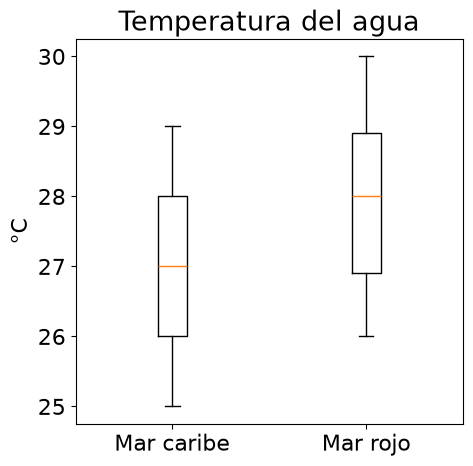

In [15]:
fig, ax = plt.subplots(1,1, figsize=(5,5))

ax.boxplot(
    x           = [grupo.values for nombre, grupo in agr_coral_ref['water_temperature']], 
    tick_labels = ['Mar caribe', 'Mar rojo']
)
ax.set_title('Temperatura del agua')
ax.set_ylabel('°C')

plt.show()

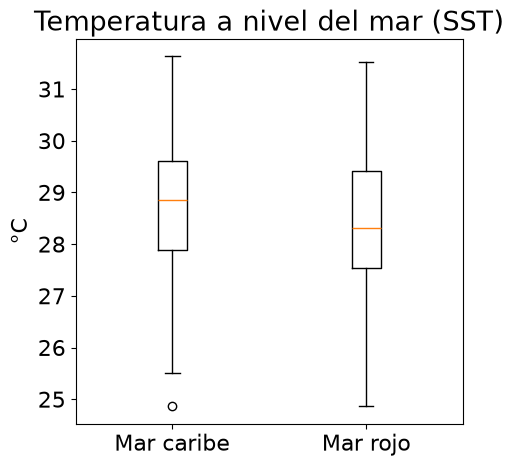

In [16]:
fig, ax = plt.subplots(1,1, figsize=(5,5))

ax.boxplot(
    x = [grupo.values for nombre, grupo in agr_ocean_climate['SST (°C)']], 
    tick_labels=['Mar caribe', 'Mar rojo']
)
ax.set_title('Temperatura a nivel del mar (SST)')
ax.set_ylabel('°C')

plt.show()

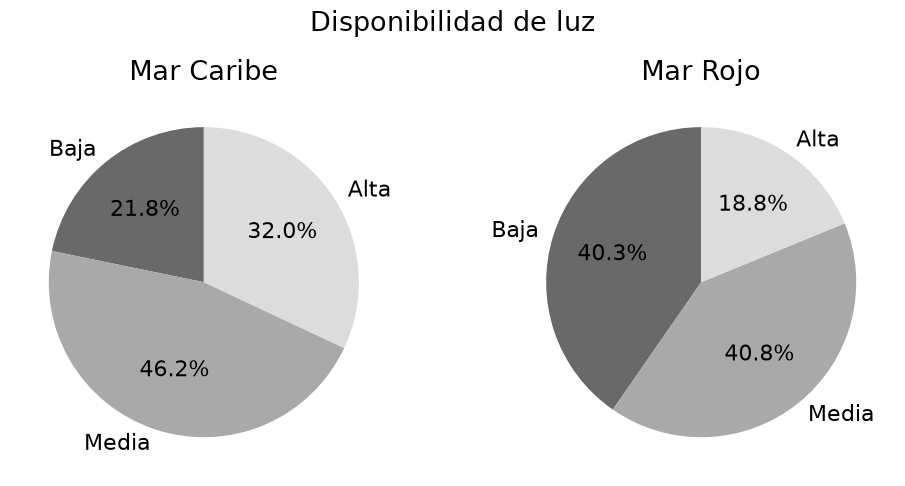

In [17]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

etiquetas = ['Baja', 'Media', 'Alta']

# Diagrama de tarta: Mar Caribe
ax1.pie(
    light_availability.caribbean_sea[['Low', 'Medium', 'High']], 
    labels=etiquetas, 
    autopct='%1.1f%%', 
    startangle=90,
    colors=['dimgray', 'darkgrey', 'gainsboro']
)
ax1.set_title('Mar Caribe')

# Diagrama de tarta: Mar Rojo
ax2.pie(
    light_availability.red_sea[['Low', 'Medium', 'High']], 
    labels=etiquetas, 
    autopct='%1.1f%%', 
    startangle=90,
    colors=['dimgray', 'darkgrey', 'gainsboro']
)
ax2.set_title('Mar Rojo')

fig.suptitle('Disponibilidad de luz')

plt.tight_layout()
plt.show()

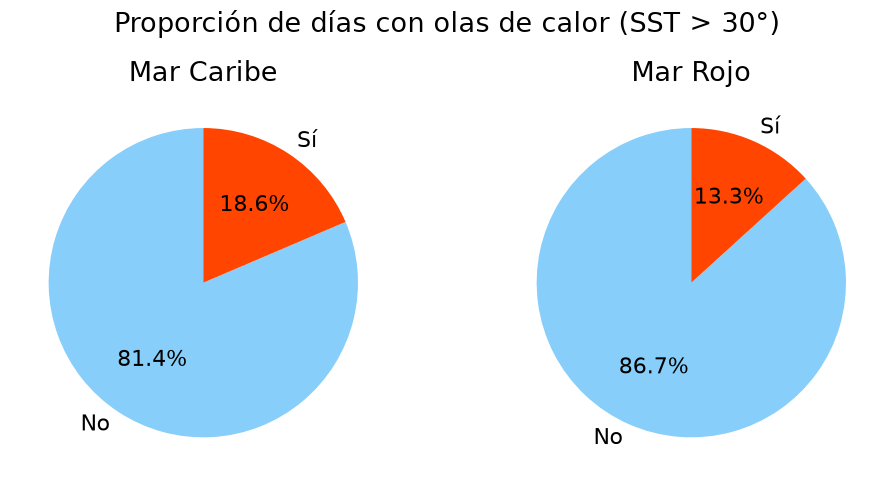

In [18]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

etiquetas = ['No', 'Sí']

ax1.pie(
    marine_heatwave.caribbean_sea, 
    labels=etiquetas, 
    autopct='%1.1f%%', # Muestra el porcentaje con 1 decimal
    startangle=90,     # Gira el gráfico para que empiece en vertical
    colors=['lightskyblue', 'orangered']
)
ax1.set_title('Mar Caribe')

ax2.pie(
    marine_heatwave.red_sea, 
    labels=etiquetas, 
    autopct='%1.1f%%', 
    startangle=90,
    colors=['lightskyblue', 'orangered']
)
ax2.set_title('Mar Rojo')

fig.suptitle('Proporción de días con olas de calor (SST > 30°)')

plt.tight_layout()
plt.show()

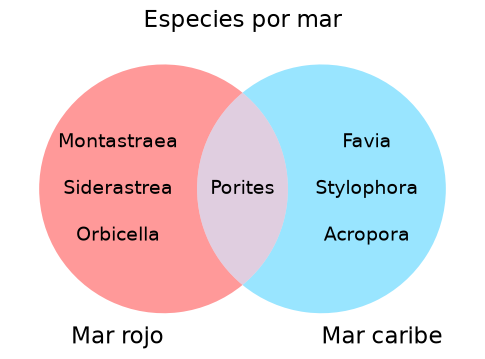

In [19]:
plt.rcParams.update({'font.size': 14})

plt.figure(figsize=(6, 6))

diagrama = venn2(
    [especies_red_sea, especies_caribbean_sea], 
    ('Mar rojo', 'Mar caribe'),
    set_colors = ('red', 'deepskyblue')
)

# Caso del mar rojo
diagrama.get_label_by_id('01').set_text('\n\n'.join(especies_red_sea - especies_caribbean_sea))
# Caso del mar caribe
diagrama.get_label_by_id('10').set_text('\n\n'.join(especies_caribbean_sea - especies_red_sea))
# Intersección
diagrama.get_label_by_id('11').set_text('\n'.join(especies_caribbean_sea & especies_red_sea))

plt.title("Especies por mar")

plt.show()

## Pregunta 2

- Comparación de regiones entre SST y número de especies para buscar patrón
	- Número de especies vs variación del SST media

- Comparación de regiones entre SST y especies por sitio para buscar patrón
	- valor del SST y especies existentes

In [20]:
columnas_especies = [
    columna for columna in coral_ref_reduced.columns if columna.startswith('species')
]

# Datos usados para la respuesta a la pregunta
ocean_climate_apt_2 = ocean_climate_reduced[
    ['Location', 'SST (°C)', 'Marine Heatwave', 'Species Observed']
]

coral_ref_apt_2 = coral_ref_reduced[['region'] + columnas_especies]

## #############################################################################
## Parte 1 de la pregunta

medias_climatica = ocean_climate_apt_2.groupby('Location').agg(
    mean_sst = ('SST (°C)', 'mean'),
    porc_ola_calor = ('Marine Heatwave', 'mean'),
    total_olas_calor = ('Marine Heatwave', 'sum'),
    total_instancias = ('Marine Heatwave', 'count')
).reset_index().set_index('Location')

numero_especies = ocean_climate_apt_2[['Location', 'Species Observed']].groupby('Location').mean()
numero_especies.columns= ['num_especies']

relacion_meteo_num_especies = medias_climatica.join(numero_especies)

## #############################################################################
## Parte 2 de la pregunta

existencia_especies = relacion_meteo_num_especies.join(
		coral_ref_apt_2.groupby('region').max()
	).dropna(axis='index')

matriz_correlacion = existencia_especies[['mean_sst', 'porc_ola_calor'] + columnas_especies].corr()
correlacion_meteo_especies = matriz_correlacion.loc[['mean_sst', 'porc_ola_calor'], columnas_especies]


### Resultados intermedios

Valores que serán representados en las gráficas

In [21]:
relacion_meteo_num_especies.round(3)

,mean_sst,porc_ola_calor,total_olas_calor,total_instancias,num_especies
Location,,,,,
caribbean_sea,28.681,0.186,13,70,118.514
galápagos,28.404,0.123,8,65,120.400
great_barrier_reef,28.469,0.092,8,87,122.379
hawaiian_islands,28.424,0.141,10,71,122.310
maldives,28.543,0.137,7,51,119.529
red_sea,28.394,0.133,11,83,122.289
south_china_sea,28.867,0.219,16,73,116.945


In [22]:
existencia_especies

,mean_sst,porc_ola_calor,total_olas_calor,total_instancias,num_especies,species_Porites,species_Favia,species_Stylophora,species_Acropora,species_Goniastrea,species_Montipora,species_Pocillopora,species_Montastraea,species_Orbicella,species_Siderastrea,species_Fungia
Location,,,,,,,,,,,,,,,,
caribbean_sea,28.681143,0.185714,13,70,118.514286,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0
great_barrier_reef,28.469195,0.091954,8,87,122.379310,1.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0
red_sea,28.394458,0.132530,11,83,122.289157,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### Visualización de estos datos

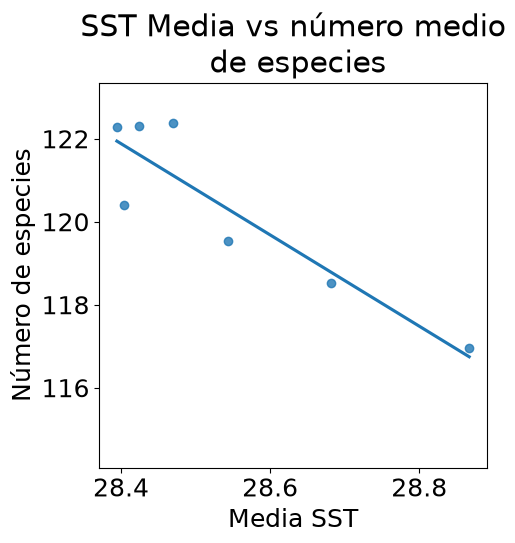

In [23]:
plt.rcParams.update({'font.size': 18})

fig, ax = plt.subplots(1, 1, figsize=(5, 5))

sns.regplot(data=relacion_meteo_num_especies, x='mean_sst', y='num_especies', ax=ax)
ax.set_title('SST Media vs número medio\n de especies')
ax.set_xlabel('Media SST')
ax.set_ylabel('Número de especies')

plt.setp(ax.collections[1], alpha=0)

plt.show()

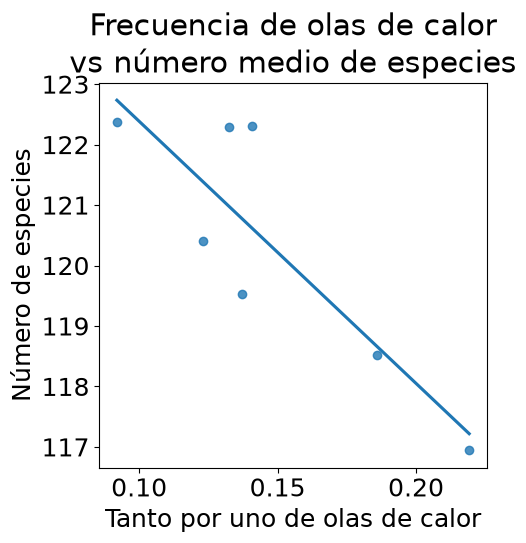

In [24]:
fig, ax = plt.subplots(1, 1, figsize=(5, 5))

sns.regplot(data=relacion_meteo_num_especies, x='porc_ola_calor', y='num_especies', ax=ax, ci=0)
ax.set_title('Frecuencia de olas de calor\nvs número medio de especies')
ax.set_xlabel('Tanto por uno de olas de calor')
ax.set_ylabel('Número de especies')

plt.show()

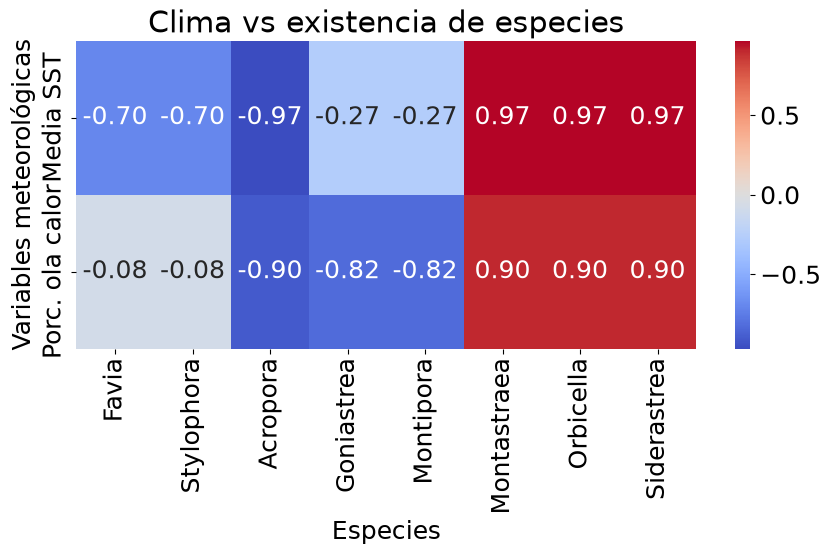

In [25]:
especies_con_correlacion = correlacion_meteo_especies.columns[~correlacion_meteo_especies.isna().all().values]
correlacion_existente_especies = correlacion_meteo_especies[especies_con_correlacion]

fig, ax = plt.subplots(1,1, figsize=(10, 4))

sns.heatmap(correlacion_existente_especies, annot=True, cmap='coolwarm', center=0, fmt=".2f")

ax.set_title('Clima vs existencia de especies')
ax.set_ylabel('Variables meteorológicas')
ax.set_xlabel('Especies')

ax.set_xticklabels([columna.split("_")[1] for columna in correlacion_existente_especies.columns])
ax.set_yticklabels(['Media SST', 'Porc. ola calor'])

plt.show()

## Pregunta 3

- Relación entre pH y blanqueaminto de los corales
	- ¿Preprocesado de los datos para completar?

In [26]:
ocean_climate_apt_3 = ocean_climate[['Location', 'pH Level', 'Bleaching Severity']]

ocean_climate_apt_3 = ocean_climate_apt_3.dropna(axis=0)

ocean_climate_apt_3['Bleaching Severity'] = pd.Categorical(
    ocean_climate_apt_3['Bleaching Severity'], 
    categories=['Low', 'Medium', 'High'], 
    ordered=True
)

### Resultado intermedio

In [27]:
ocean_climate_apt_3.groupby(['Location', 'Bleaching Severity']).describe()

pH Level                             \
                                         count      mean       std    min   
Location           Bleaching Severity                                       
caribbean_sea      Low                    16.0  8.046000  0.058271  7.921   
                   Medium                 19.0  8.046789  0.060474  7.966   
                   High                   15.0  8.027800  0.065320  7.932   
galápagos          Low                    19.0  8.052421  0.049062  7.941   
                   Medium                 13.0  8.042846  0.046842  7.939   
                   High                    9.0  8.045333  0.045730  7.944   
great_barrier_reef Low                    24.0  8.048625  0.055605  7.944   
                   Medium                 24.0  8.047083  0.058572  7.968   
                   High                   14.0  8.047786  0.050665  7.963   
hawaiian_islands   Low                    20.0  8.043500  0.042818  7.962   
                   Medium                 17.0  8.062118  0.060425  7.961   
                   High                   16.0  8.045687  0.065245  7.893   
maldives           Low                    19.0  8.052684  0.044803  7.973   
                   Medium                 12.0  8.068583  0.057116  7.952   
                   High                    7.0  8.062857  0.035040  8.002   
red_sea            Low                    15.0  8.066267  0.059670  7.944   
                   Medium                 18.0  8.055611  0.062245  7.942   
                   High                   19.0  8.062316  0.063055  7.974   
south_china_sea    Low                    19.0  8.047053  0.048114  7.954   
                   Medium                 27.0  8.038556  0.059477  7.953   
                   High                    8.0  8.034250  0.038410  7.989   

                                                                        
                                           25%     50%      75%    max  
Location           Bleaching Severity                                   
caribbean_sea      Low                 8.00850  8.0465  8.07275  8.164  
                   Medium              7.99150  8.0440  8.09100  8.182  
                   High                7.97850  8.0260  8.05150  8.173  
galápagos          Low                 8.03300  8.0530  8.07150  8.158  
                   Medium              8.02200  8.0550  8.07600  8.107  
                   High                8.03200  8.0530  8.06700  8.100  
great_barrier_reef Low                 8.01550  8.0535  8.08625  8.160  
                   Medium              7.99225  8.0485  8.08225  8.171  
                   High                8.00500  8.0605  8.08450  8.120  
hawaiian_islands   Low                 8.01275  8.0380  8.06325  8.132  
                   Medium              8.00900  8.0730  8.11000  8.167  
                   High                7.99200  8.0590  8.08100  8.140  
maldives           Low                 8.03550  8.0500  8.08050  8.124  
                   Medium              8.04275  8.0735  8.10225  8.151  
                   High                8.05300  8.0560  8.08000  8.116  
red_sea            Low                 8.02950  8.0680  8.09900  8.171  
                   Medium              8.01400  8.0640  8.09300  8.167  
                   High                8.00200  8.0580  8.11850  8.173  
south_china_sea    Low                 8.02400  8.0610  8.08050  8.112  
                   Medium              7.98950  8.0480  8.07200  8.146  
                   High                8.00300  8.0310  8.06375  8.094

### Visualización

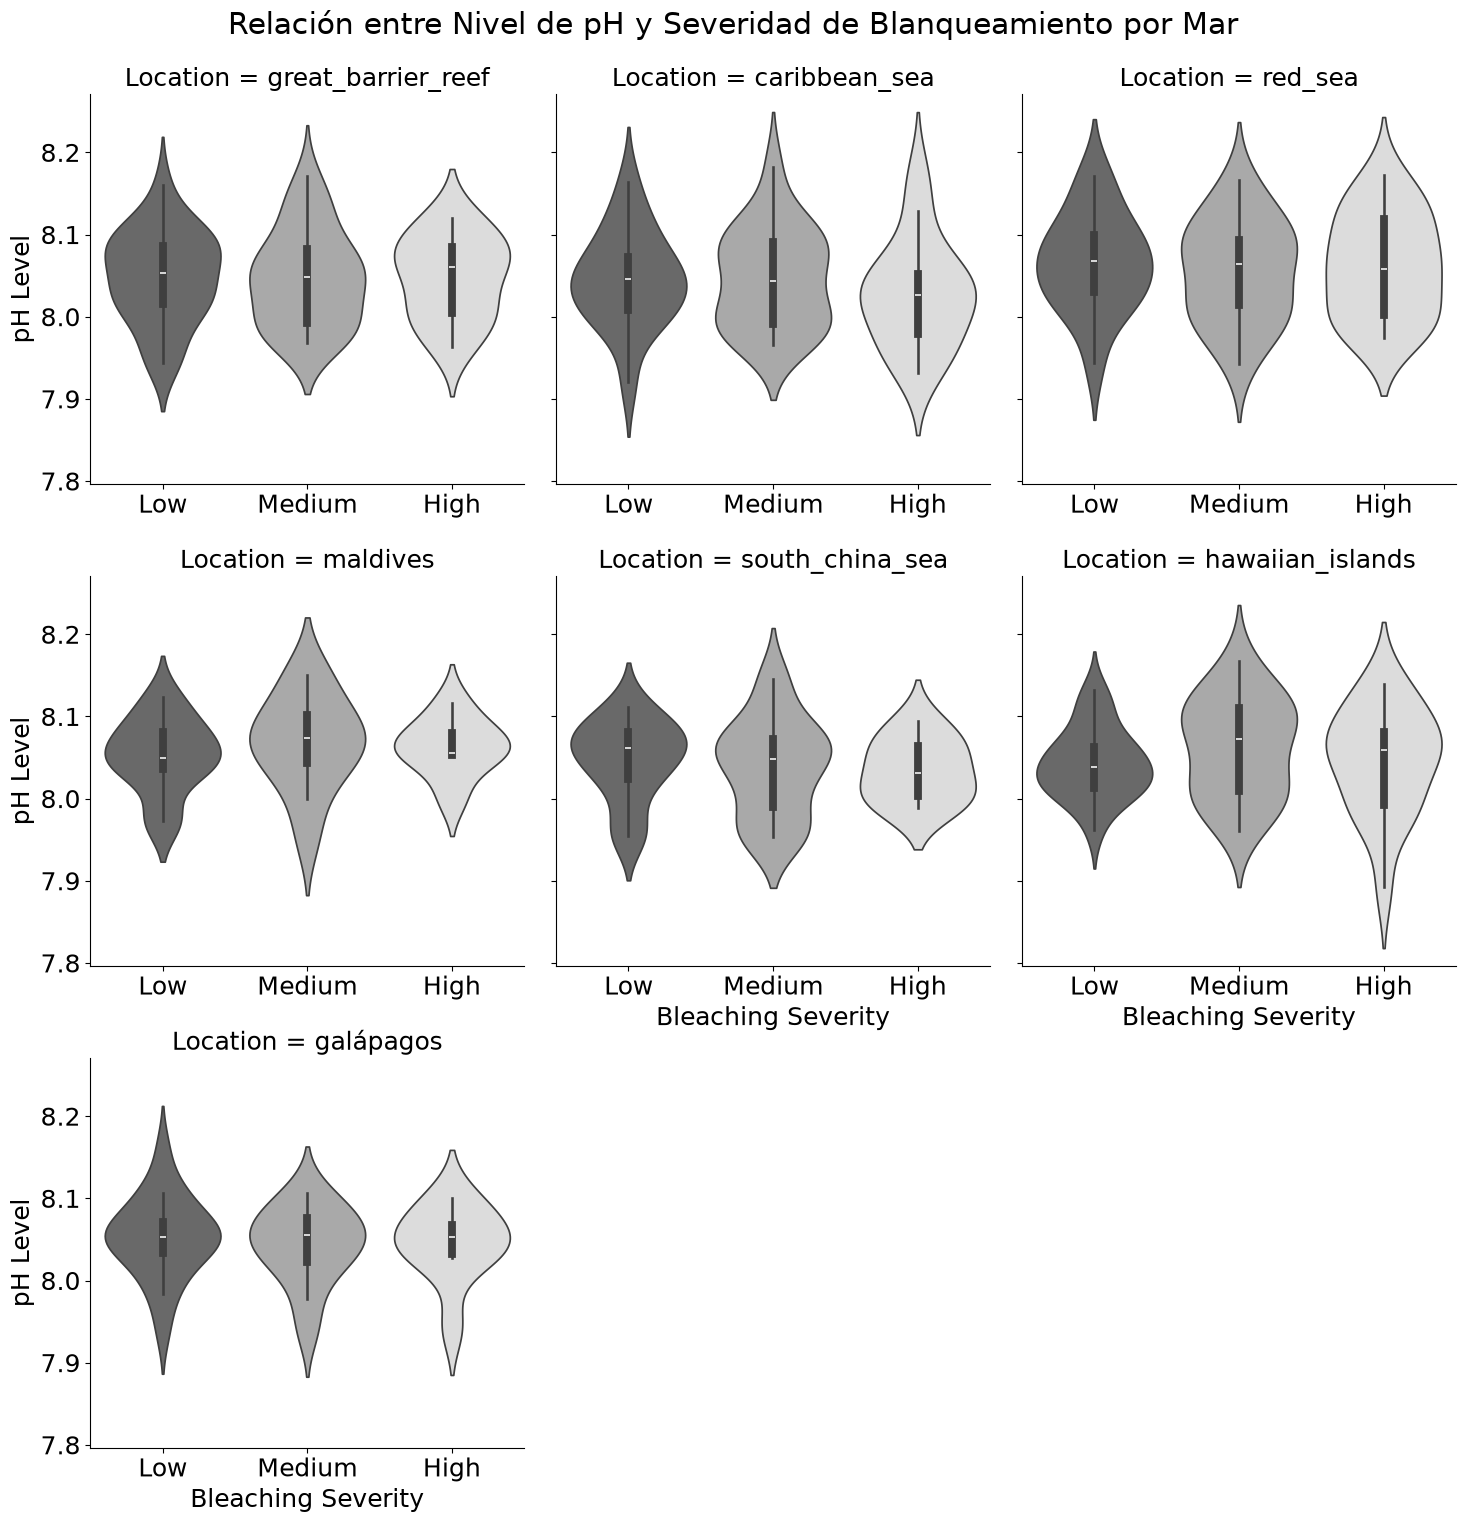

In [28]:
sns.catplot(
    data	= ocean_climate_apt_3, 
    x		= 'Bleaching Severity',
    hue		= 'Bleaching Severity',
    y		= 'pH Level', 
	col		= 'Location',
    palette	= ['gainsboro', 'darkgrey', 'dimgray'],
    col_wrap = 3,
    sharex	= False,
    kind	= "violin",
    dodge	= False
)

plt.suptitle('Relación entre Nivel de pH y Severidad de Blanqueamiento por Mar', y=1.02)

plt.show()